In [51]:
%pip install langdetect

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [64]:
!pip install nltk textblob wordcloud vaderSentiment
!pip install nltk textblob wordcloud vaderSentiment seaborn scikit-learn

import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
from textblob import TextBlob
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from wordcloud import WordCloud, STOPWORDS

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)




[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [53]:
df = pd.read_csv('youtube_comments.csv', encoding='utf-8')


In [54]:
df.head(5)

,video_id,video_title,comment
0,TcMBFSGVi1c,Avengers Endgame Trailer,Furei a boca com espinho de peixe
1,TcMBFSGVi1c,Avengers Endgame Trailer,Sou budista Jesus Cristo
2,TcMBFSGVi1c,Avengers Endgame Trailer,Is there any chance of iron man returning back in present 🤕
3,TcMBFSGVi1c,Avengers Endgame Trailer,TOMORROW. DOOM COMES FOR US ALL.
4,TcMBFSGVi1c,Avengers Endgame Trailer,saw this movie again today


In [61]:
import pandas as pd
from langdetect import detect, DetectorFactory

# Make language detection deterministic across runs
DetectorFactory.seed = 42

# 1. Drop empty comments first
df = df.dropna(subset=['comment', 'video_title']).copy()

# 2. Filter for Avengers videos (case-insensitive)
avengers_df = df[df['video_title'].str.contains('avengers', case=False, na=False)].copy()

# 3. Helper function to safely detect English text
def is_english(text):
    try:
        return detect(str(text)) == 'en'
    except:
        return False

# 4. Keep only English comments
avengers_en_df = avengers_df[avengers_df['comment'].apply(is_english)].copy()

print(f"Total rows: {len(df)}")
print(f"Avengers rows: {len(avengers_df)}")
print(f"Avengers + English rows: {len(avengers_en_df)}")

# Save filtered
avengers_en_df.to_csv('Avengers_Movie_trailer_review.csv', index=False, encoding='utf-8-sig')

Total rows: 66802
Avengers rows: 8409
Avengers + English rows: 5294


PermissionError: [Errno 13] Permission denied: 'Avengers_Movie_trailer_review.csv'

In [ ]:
avengers_en_df.head(5)

,video_id,video_title,comment
1,TcMBFSGVi1c,Avengers Endgame Trailer,Sou budista Jesus Cristo
2,TcMBFSGVi1c,Avengers Endgame Trailer,Is there any chance of iron man returning back in present 🤕
4,TcMBFSGVi1c,Avengers Endgame Trailer,saw this movie again today
5,TcMBFSGVi1c,Avengers Endgame Trailer,i’m discovering plot elements watching this trailer years later 😓
7,TcMBFSGVi1c,Avengers Endgame Trailer,I was too young to have known about avengers when this masterpiece came out. I've regretted not being able to watch not even one of the movies of this epic franchise in the theatres...when it came out...with the whole fandom🔥😭🥺 I can only hope doomsday would fill that gap for me😭♥️😔


# Open the newly saved file

In [56]:
Avengers_trailer = pd.read_csv('Avengers_Movie_trailer_review.csv')

In [63]:
Avengers_trailer.head(5)

,video_id,video_title,comment
0,TcMBFSGVi1c,Avengers Endgame Trailer,Sou budista Jesus Cristo
1,TcMBFSGVi1c,Avengers Endgame Trailer,Is there any chance of iron man returning back in present 🤕
2,TcMBFSGVi1c,Avengers Endgame Trailer,saw this movie again today
3,TcMBFSGVi1c,Avengers Endgame Trailer,i’m discovering plot elements watching this trailer years later 😓
4,TcMBFSGVi1c,Avengers Endgame Trailer,I was too young to have known about avengers when this masterpiece came out. I've regretted not being able to watch not even one of the movies of this epic franchise in the theatres...when it came out...with the whole fandom🔥😭🥺 I can only hope doomsday would fill that gap for me😭♥️😔


In [58]:
LABELS = ["negative", "neutral", "positive"]

# Exploratory Data Analysis

KeyError: 'sentiment'

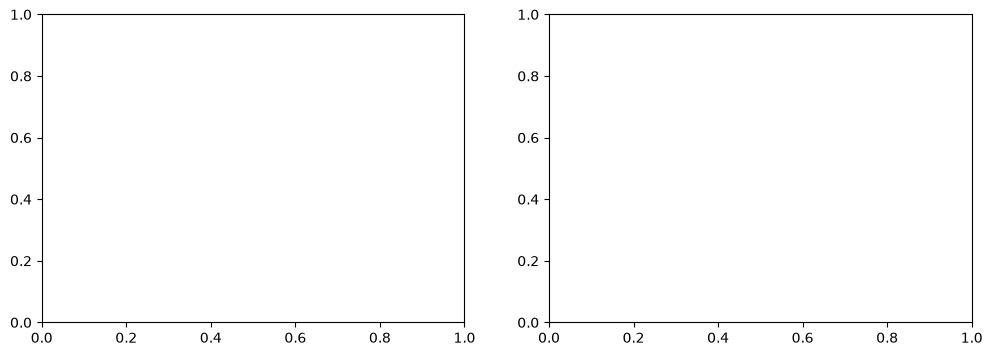

In [65]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# 1. Plot overall sentiment using your 'Avengers_trailer' dataframe and a 'sentiment' column
Avengers_trailer["sentiment"].value_counts().reindex(LABELS).plot.bar(
    ax=axes[0], color=["maroon", "gray", "green"]
)
axes[0].set_title("Overall Sentiment (Human Label)")

# 2. Group by 'video_title' (actual column name) instead of "Avengers_trailer"
pd.crosstab(
    Avengers_trailer["video_title"],
    Avengers_trailer["sentiment"],
    normalize="index",
)[LABELS].plot.barh(
    stacked=True, ax=axes[1], color=["maroon", "gray", "green"]
)
axes[1].set_title("Sentiment Mix per Avengers trailer")

plt.tight_layout()
plt.show()


In [ ]:
def clean_tweet(text):
    text = re.sub(r"http\S+|www\.\S+", " ", text)   # URLs
    text = re.sub(r"@\w+", " ", text)               # @mentions
    text = text.replace("&amp;", "&").replace("#", "")
    return re.sub(r"\s+", " ", text).strip()

df['clean'] = df["text"].apply(clean_tweet)
df[['text', 'clean']].sample(5)